# F1 – Risque de crédit en Allemagne
**Nom et prénom :** Mizeb Lina **Code Apogée :** 25007611 **Groupe :** grpfin3
**Filière :** S7 FIN / S7 CI **Date :** 17/11/2026
**Dépôt GitHub :** https://github.com/mizeblina1477encg-png/25007611-mizeblina-grpfin3

## 1. Sujet et problématique
- **Intérêt du sujet** : Une banque doit décider d'accorder ou non un crédit. Refuser un bon client fait perdre un gain, mais accorder un crédit à un mauvais payeur coûte beaucoup plus cher. Le résultat sert à un analyste crédit pour fixer une règle de décision.
- **Problématique** : Un modèle de scoring avec un seuil de décision optimisé permet-il de réduire le coût moyen par dossier, par rapport à une règle naïve, quand accorder un crédit à un mauvais payeur coûte 5 fois plus que refuser un bon client ?
- **Objectif mesurable** : Coût moyen par dossier = (5 × FN + 1 × FP) / n, sur un jeu de test stratifié de 30 %. Référence : meilleure règle naïve (tout accorder ou tout refuser). Seuil de réussite : coût inférieur d'au moins 20 % à la référence.
- **Nature du problème** : Classification binaire à coûts asymétriques (cible à deux modalités, bon ou mauvais payeur, avec des erreurs de coût différent).
- **Algorithme principal envisagé** : n°8, régression logistique (probabilités, interprétable, adaptée à 1 000 observations).

In [1]:
import zipfile, os
import pandas as pd

with zipfile.ZipFile("/content/archive.zip") as z:
    print(z.namelist())          # noms des fichiers contenus dans le zip
    z.extractall("/content/data")

print(os.listdir("/content/data"))

['german_credit_data.csv']
['german_credit_data.csv']


In [2]:
df = pd.read_csv("/content/data/german_credit_data.csv")
print(df.shape)
print(df.columns.tolist())
print(df.iloc[:, -1].value_counts())
print("Valeurs manquantes :", df.isna().sum().sum())
df.head()

(1000, 21)
['laufkont', 'laufzeit', 'moral', 'verw', 'hoehe', 'sparkont', 'beszeit', 'rate', 'famges', 'buerge', 'wohnzeit', 'verm', 'alter', 'weitkred', 'wohn', 'bishkred', 'beruf', 'pers', 'telef', 'gastarb', 'kredit']
kredit
1    700
0    300
Name: count, dtype: int64
Valeurs manquantes : 0


,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,...,verm,alter,weitkred,wohn,bishkred,beruf,pers,telef,gastarb,kredit
0,1,18,4,2,1049,1,2,4,2,1,...,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,...,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,...,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,...,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,...,2,38,1,2,2,2,2,1,1,1


In [3]:
from pathlib import Path
import numpy as np

GRAINE = 42
np.random.seed(GRAINE)

print(df.dtypes.value_counts())
print("Doublons :", df.duplicated().sum())
print(df.nunique().sort_values())
df[["laufzeit", "hoehe", "alter"]].describe()

int64    21
Name: count, dtype: int64
Doublons : 0
kredit        2
gastarb       2
telef         2
pers          2
weitkred      3
wohn          3
buerge        3
laufkont      4
bishkred      4
rate          4
wohnzeit      4
beruf         4
famges        4
verm          4
moral         5
sparkont      5
beszeit       5
verw         10
laufzeit     33
alter        53
hoehe       923
dtype: int64


,laufzeit,hoehe,alter
count,1000.000000,1000.00000,1000.00000
mean,20.903000,3271.24800,35.54200
std,12.058814,2822.75176,11.35267
min,4.000000,250.00000,19.00000
25%,12.000000,1365.50000,27.00000
50%,18.000000,2319.50000,33.00000
75%,24.000000,3972.25000,42.00000
max,72.000000,18424.00000,75.00000


In [4]:
# Cible : 1 = mauvais payeur (risque), 0 = bon payeur
y = (df["kredit"] == 0).astype(int)
X = df.drop(columns="kredit")

print(y.value_counts())
print("Taux de mauvais payeurs :", y.mean())

# Matrice de coûts
COUT_FN = 5   # accorder un crédit à un mauvais payeur
COUT_FP = 1   # refuser un bon payeur
print("Seuil théorique sur P(mauvais) :", COUT_FP / (COUT_FP + COUT_FN))

kredit
0    700
1    300
Name: count, dtype: int64
Taux de mauvais payeurs : 0.3
Seuil théorique sur P(mauvais) : 0.16666666666666666


In [5]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

GRAINE = 42
np.random.seed(GRAINE)

print("Python :", sys.version.split()[0])
print("pandas :", pd.__version__, "| numpy :", np.__version__, "| scikit-learn :", sklearn.__version__)

df = pd.read_csv("/content/data/german_credit_data.csv")
print(df.shape)
print("Doublons :", df.duplicated().sum())
print("Valeurs manquantes :", df.isna().sum().sum())
print(df["kredit"].value_counts())

Python : 3.13.18
pandas : 2.2.3 | numpy : 2.4.6 | scikit-learn : 1.6.1
(1000, 21)
Doublons : 0
Valeurs manquantes : 0
kredit
1    700
0    300
Name: count, dtype: int64


In [6]:
print(df.dtypes.value_counts())
print(df.nunique().sort_values())
df[["laufzeit", "hoehe", "alter"]].describe()

int64    21
Name: count, dtype: int64
kredit        2
gastarb       2
telef         2
pers          2
weitkred      3
wohn          3
buerge        3
laufkont      4
bishkred      4
rate          4
wohnzeit      4
beruf         4
famges        4
verm          4
moral         5
sparkont      5
beszeit       5
verw         10
laufzeit     33
alter        53
hoehe       923
dtype: int64


,laufzeit,hoehe,alter
count,1000.000000,1000.00000,1000.00000
mean,20.903000,3271.24800,35.54200
std,12.058814,2822.75176,11.35267
min,4.000000,250.00000,19.00000
25%,12.000000,1365.50000,27.00000
50%,18.000000,2319.50000,33.00000
75%,24.000000,3972.25000,42.00000
max,72.000000,18424.00000,75.00000


- **Nom et source** : German Credit Data, publié sur Kaggle par varunchawla30 (https://www.kaggle.com/datasets/varunchawla30/german-credit-data). Il s'agit d'une version du jeu Statlog German Credit de l'UCI. **Date d'extraction : 17/11/2026.**
- **Licence** : aucune licence indiquée sur la page de téléchargement.
- **Taille** : 1 000 observations, 21 variables (20 explicatives + 1 cible). Pas de dimension temporelle (données en coupe).
- **Unité d'observation** : un dossier de demande de crédit.
- **Variable cible** : `kredit` (1 = bon payeur, 0 = mauvais payeur). Je construis `y = 1` pour un mauvais payeur (risque), afin que la classe positive soit la classe coûteuse.
- **Adéquation** : le jeu contient des dossiers dont l'issue est observée, ce qui permet d'estimer une probabilité de défaut et d'optimiser un seuil de décision selon la matrice de coûts 5:1.
- **Limites** :
  - Données anciennes (crédits allemands, montants en deutsche marks) : elles ne représentent pas les clients d'aujourd'hui.
  - Seulement 300 mauvais payeurs sur 1 000 : le seuil optimal sera estimé avec du bruit.
  - Biais de sélection : on observe uniquement des clients à qui un crédit a été accordé, pas les refusés.
  - La matrice de coûts 5:1 est une convention du jeu d'origine, pas une mesure réelle des pertes d'une banque.

| Variable | Description | Type | Unité | Rôle | Manquants (%) |
|---|---|---|---|---|---|
| kredit | Risque de crédit (1 = bon, 0 = mauvais) | binaire | – | cible d'origine | 0 |
| y (créée) | 1 si kredit = 0 (mauvais payeur), sinon 0 | binaire | – | cible utilisée | 0 |
| laufzeit | Durée du crédit | numérique | mois | explicative | 0 |
| hoehe | Montant du crédit | numérique | DM | explicative | 0 |
| alter | Âge du client | numérique | années | explicative | 0 |
| laufkont | Statut du compte courant (1 = aucun, 2 = < 0 DM, 3 = 0 à 200 DM, 4 = ≥ 200 DM) | catégorielle | – | explicative | 0 |
| moral | Historique de crédit (0 à 4) | catégorielle | – | explicative | 0 |
| sparkont | Épargne | catégorielle | – | explicative | 0 |
| verw | Objet du crédit | catégorielle | – | explicative | 0 |

In [7]:
y = (df["kredit"] == 0).astype(int)   # 1 = mauvais payeur
X = df.drop(columns="kredit")

print(y.value_counts())
print("Taux de mauvais payeurs :", y.mean())
df[["laufzeit", "hoehe", "alter"]].describe()

kredit
0    700
1    300
Name: count, dtype: int64
Taux de mauvais payeurs : 0.3


,laufzeit,hoehe,alter
count,1000.000000,1000.00000,1000.00000
mean,20.903000,3271.24800,35.54200
std,12.058814,2822.75176,11.35267
min,4.000000,250.00000,19.00000
25%,12.000000,1365.50000,27.00000
50%,18.000000,2319.50000,33.00000
75%,24.000000,3972.25000,42.00000
max,72.000000,18424.00000,75.00000


In [8]:
for col in ["laufzeit", "hoehe", "alter"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    borne = q3 + 1.5 * (q3 - q1)
    print(col, ": valeurs au-dessus de", round(borne, 1), "->", (df[col] > borne).sum(), "dossiers")

laufzeit : valeurs au-dessus de 42.0 -> 70 dossiers
hoehe : valeurs au-dessus de 7882.4 -> 72 dossiers
alter : valeurs au-dessus de 64.5 -> 23 dossiers


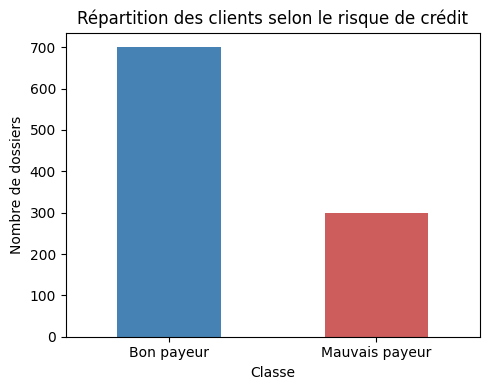

In [9]:
import os
os.makedirs("figures", exist_ok=True)

# Graphique 1 : répartition de la cible
fig, ax = plt.subplots(figsize=(5, 4))
y.map({0: "Bon payeur", 1: "Mauvais payeur"}).value_counts().plot(kind="bar", ax=ax, color=["steelblue", "indianred"])
ax.set_title("Répartition des clients selon le risque de crédit")
ax.set_xlabel("Classe")
ax.set_ylabel("Nombre de dossiers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("figures/01_repartition_cible.png", dpi=150)
plt.show()

**Interprétation.** Le jeu contient 700 bons payeurs et 300 mauvais payeurs, soit 30 % de mauvais. Les classes sont déséquilibrées. Je n'utiliserai donc pas l'accuracy : un modèle qui accorde tous les crédits aurait 70 % de bonnes réponses tout en étant le plus coûteux. La métrique principale sera le coût moyen (5 × FN + 1 × FP) / n, et les découpages seront stratifiés.

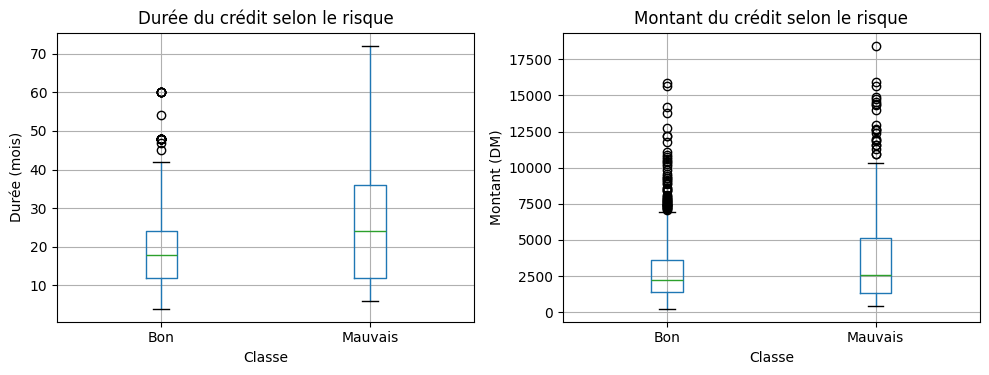

In [10]:
# Graphique 2 : durée et montant selon le risque
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df.assign(risque=y.map({0: "Bon", 1: "Mauvais"})).boxplot(column="laufzeit", by="risque", ax=axes[0])
axes[0].set_title("Durée du crédit selon le risque")
axes[0].set_xlabel("Classe")
axes[0].set_ylabel("Durée (mois)")
df.assign(risque=y.map({0: "Bon", 1: "Mauvais"})).boxplot(column="hoehe", by="risque", ax=axes[1])
axes[1].set_title("Montant du crédit selon le risque")
axes[1].set_xlabel("Classe")
axes[1].set_ylabel("Montant (DM)")
plt.suptitle("")
plt.tight_layout()
plt.savefig("figures/02_duree_montant.png", dpi=150)
plt.show()

**Interprétation.** La durée médiane est plus élevée chez les mauvais payeurs (environ 24 mois contre 18 pour les bons), et leurs durées vont jusqu'à 72 mois : les crédits longs semblent plus risqués. Pour le montant, les médianes sont proches (environ 2 550 DM contre 2 250) et les boîtes se chevauchent largement : le montant seul sépare mal les deux classes. On voit de nombreuses valeurs élevées (jusqu'à environ 18 000 DM) dans les deux groupes. Je les conserve : ce sont des crédits réels et non des erreurs de saisie.

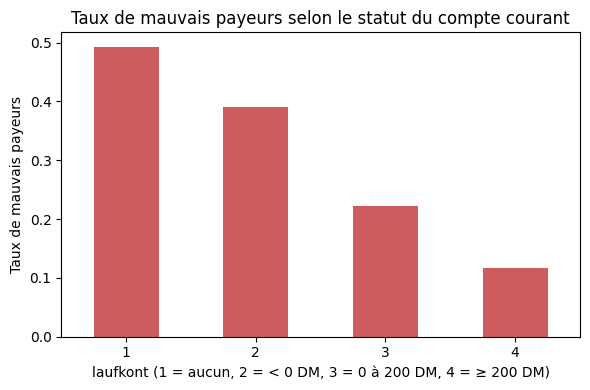

laufkont
1    0.492701
2    0.390335
3    0.222222
4    0.116751
Name: kredit, dtype: float64


In [11]:
# Graphique 3 : taux de mauvais payeurs selon le statut du compte courant
taux = y.groupby(df["laufkont"]).mean()
fig, ax = plt.subplots(figsize=(6, 4))
taux.plot(kind="bar", ax=ax, color="indianred")
ax.set_title("Taux de mauvais payeurs selon le statut du compte courant")
ax.set_xlabel("laufkont (1 = aucun, 2 = < 0 DM, 3 = 0 à 200 DM, 4 = ≥ 200 DM)")
ax.set_ylabel("Taux de mauvais payeurs")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("figures/03_taux_par_statut_compte.png", dpi=150)
plt.show()
print(taux)

**Interprétation.** Le taux de mauvais payeurs diminue nettement quand le code de `laufkont` augmente : 49,3 % pour le code 1, 39,0 % pour le code 2, 22,2 % pour le code 3 et 11,7 % pour le code 4. Cette variable est donc très discriminante et devrait compter parmi les plus importantes du modèle. Je ne tire pas de conclusion sur le sens économique des codes, car leur description semble incohérente avec ces taux (voir limites). Il s'agit d'une association, pas d'une causalité.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Découpage stratifié AVANT toute transformation
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=GRAINE
)
print(X_train.shape, X_test.shape)
print("Taux de mauvais (train) :", y_train.mean(), "| (test) :", y_test.mean())

# Préparation (non encore ajustée : elle le sera dans le Pipeline)
num_cols = ["laufzeit", "hoehe", "alter", "rate", "wohnzeit", "bishkred", "pers"]
cat_cols = [c for c in X.columns if c not in num_cols]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
print("Numériques :", num_cols)
print("Catégorielles :", cat_cols)

(700, 20) (300, 20)
Taux de mauvais (train) : 0.3 | (test) : 0.3
Numériques : ['laufzeit', 'hoehe', 'alter', 'rate', 'wohnzeit', 'bishkred', 'pers']
Catégorielles : ['laufkont', 'moral', 'verw', 'sparkont', 'beszeit', 'famges', 'buerge', 'verm', 'weitkred', 'wohn', 'beruf', 'telef', 'gastarb']


In [14]:
def cout_moyen(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    fn = ((y_true == 1) & (y_pred == 0)).sum()   # mauvais payeur accepté : coût 5
    fp = ((y_true == 0) & (y_pred == 1)).sum()   # bon payeur refusé : coût 1
    return (5 * fn + 1 * fp) / len(y_true)

print("Tout accorder :", cout_moyen(y_train, np.zeros(len(y_train))))
print("Tout refuser  :", cout_moyen(y_train, np.ones(len(y_train))))

Tout accorder : 1.5
Tout refuser  : 0.7


**Référence naïve.** Sur l'apprentissage, « tout accorder » donne un coût moyen de 1,5 et « tout refuser » de 0,7. La meilleure référence est donc « tout refuser » (0,7). Seuil de réussite fixé avant le test : coût moyen ≤ 0,56 (20 % de moins que la référence).
**Métriques.** Principale : coût moyen = (5 × FN + 1 × FP) / n. Secondaires : AUC et rappel de la classe « mauvais payeur ».
**Découpage.** 70 % apprentissage, 30 % test, stratifié, graine 42. Réglage par validation croisée stratifiée à 5 plis sur l'apprentissage uniquement ; le test n'est utilisé qu'une fois, à la fin.

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)
pipe = Pipeline([("prep", preprocess),
                 ("clf", LogisticRegression(max_iter=1000))])

grille = {"clf__C": [0.01, 0.1, 1, 10]}
gs = GridSearchCV(pipe, grille, scoring="roc_auc", cv=cv, return_train_score=True)
gs.fit(X_train, y_train)

print("Meilleur C :", gs.best_params_)
print("AUC validation (moyenne, écart-type) :",
      round(gs.best_score_, 3), "±", round(gs.cv_results_["std_test_score"][gs.best_index_], 3))

Meilleur C : {'clf__C': 1}
AUC validation (moyenne, écart-type) : 0.793 ± 0.018


Seuil optimal : 0.17 | coût moyen (validation croisée) : 0.53
Coût à 0,5 : 0.853
Coût au seuil théorique 1/6 : 0.533


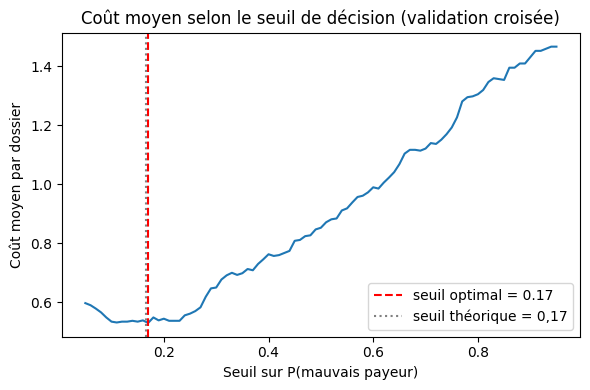

In [18]:
modele = gs.best_estimator_
p_oof = cross_val_predict(modele, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

seuils = np.linspace(0.05, 0.95, 91)
couts = [cout_moyen(y_train, (p_oof >= s).astype(int)) for s in seuils]
seuil_opt = seuils[int(np.argmin(couts))]
print("Seuil optimal :", round(seuil_opt, 2), "| coût moyen (validation croisée) :", round(min(couts), 3))
print("Coût à 0,5 :", round(cout_moyen(y_train, (p_oof >= 0.5).astype(int)), 3))
print("Coût au seuil théorique 1/6 :", round(cout_moyen(y_train, (p_oof >= 1/6).astype(int)), 3))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(seuils, couts)
ax.axvline(seuil_opt, color="red", linestyle="--", label=f"seuil optimal = {seuil_opt:.2f}")
ax.axvline(1/6, color="gray", linestyle=":", label="seuil théorique = 0,17")
ax.set_title("Coût moyen selon le seuil de décision (validation croisée)")
ax.set_xlabel("Seuil sur P(mauvais payeur)")
ax.set_ylabel("Coût moyen par dossier")
ax.legend()
plt.tight_layout()
plt.savefig("figures/04_cout_selon_seuil.png", dpi=150)
plt.show()

**Interprétation.** Le coût moyen est minimal pour un seuil d'environ 0,17 (0,53 en validation croisée), ce qui coïncide avec le seuil théorique 1/6 ≈ 0,167 déduit de la matrice de coûts (refuser dès que 5·p > 1−p). Avec le seuil habituel de 0,5, le coût monte à 0,853, soit plus que la règle « tout refuser » (0,70) : un seuil à 0,5 serait donc inadapté quand un faux négatif coûte 5 fois plus. La courbe est presque plate entre 0,10 et 0,27 : le résultat est peu sensible au choix exact du seuil dans cette zone. Le coût de 0,53 est légèrement optimiste, car le seuil a été choisi sur ces mêmes prédictions hors-pli ; le test dira ce qu'il en est.

In [19]:
from sklearn.metrics import roc_auc_score, confusion_matrix, recall_score

p_test = modele.predict_proba(X_test)[:, 1]
pred_test = (p_test >= seuil_opt).astype(int)

res = pd.DataFrame({
    "Méthode": ["Tout accorder", "Tout refuser", f"Régression logistique (seuil {seuil_opt:.2f})"],
    "Coût moyen (validation)": [
        cout_moyen(y_train, np.zeros(len(y_train))),
        cout_moyen(y_train, np.ones(len(y_train))),
        min(couts)],
    "Coût moyen (test)": [
        cout_moyen(y_test, np.zeros(len(y_test))),
        cout_moyen(y_test, np.ones(len(y_test))),
        cout_moyen(y_test, pred_test)],
})
print(res.round(3).to_string(index=False))

print("\nAUC test :", round(roc_auc_score(y_test, p_test), 3))
print("Rappel des mauvais payeurs (test) :", round(recall_score(y_test, pred_test), 3))
print("Matrice de confusion (lignes = réel 0/1, colonnes = prédit 0/1) :")
print(confusion_matrix(y_test, pred_test))

                           Méthode  Coût moyen (validation)  Coût moyen (test)
                     Tout accorder                     1.50               1.50
                      Tout refuser                     0.70               0.70
Régression logistique (seuil 0.17)                     0.53               0.62

AUC test : 0.75
Rappel des mauvais payeurs (test) : 0.822
Matrice de confusion (lignes = réel 0/1, colonnes = prédit 0/1) :
[[104 106]
 [ 16  74]]


**Interprétation.** Sur le test, la régression logistique avec un seuil de 0,17 obtient un coût moyen de 0,62, contre 0,70 pour la meilleure référence naïve (tout refuser) et 1,50 pour tout accorder. La réduction est de 11 % par rapport à la meilleure référence, inférieure à l'objectif de 20 % (coût ≤ 0,56) : **l'objectif n'est pas atteint**. Le coût en validation croisée (0,53) était plus optimiste, car le seuil y a été choisi sur ces mêmes prédictions. L'AUC passe de 0,79 en validation à 0,75 au test.

   param_clf__C  mean_train_score  mean_test_score
0          0.01             0.815            0.771
1          0.10             0.847            0.792
2          1.00             0.861            0.793
3         10.00             0.863            0.789


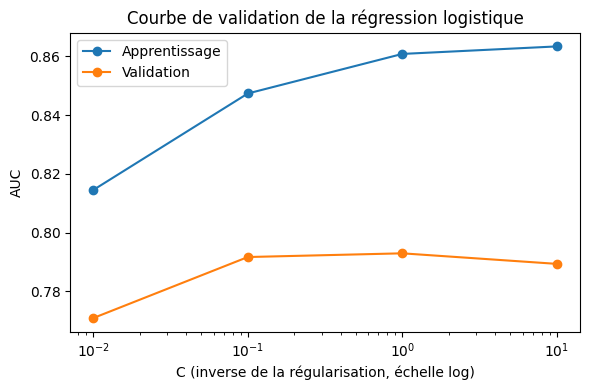

In [20]:
# Surapprentissage : AUC apprentissage vs validation selon C
r = pd.DataFrame(gs.cv_results_)[["param_clf__C", "mean_train_score", "mean_test_score"]]
print(r.round(3))

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogx(r["param_clf__C"].astype(float), r["mean_train_score"], marker="o", label="Apprentissage")
ax.semilogx(r["param_clf__C"].astype(float), r["mean_test_score"], marker="o", label="Validation")
ax.set_title("Courbe de validation de la régression logistique")
ax.set_xlabel("C (inverse de la régularisation, échelle log)")
ax.set_ylabel("AUC")
ax.legend()
plt.tight_layout()
plt.savefig("figures/05_courbe_validation.png", dpi=150)
plt.show()

**Interprétation.** L'AUC d'apprentissage (0,86 pour C = 1) est supérieure à celle de validation (0,79) : il y a un surapprentissage modéré. Réduire C pour le limiter dégrade la validation (0,77 pour C = 0,01), donc C = 1 est un compromis raisonnable. Le choix est peu sensible entre C = 0,1 et C = 10 (validation entre 0,789 et 0,793).

In [21]:
# Analyse des erreurs et illustration sur 5 clients du test
analyse = X_test.copy()
analyse["reel"] = y_test.values
analyse["proba_mauvais"] = p_test.round(3)
analyse["prediction"] = pred_test

fn = analyse[(analyse.reel == 1) & (analyse.prediction == 0)]
fp = analyse[(analyse.reel == 0) & (analyse.prediction == 1)]
print("Faux négatifs (coût 5) :", len(fn), "| Faux positifs (coût 1) :", len(fp))

analyse[["laufzeit", "hoehe", "alter", "laufkont", "proba_mauvais", "prediction", "reel"]].sample(5, random_state=GRAINE)

Faux négatifs (coût 5) : 16 | Faux positifs (coût 1) : 106


,laufzeit,hoehe,alter,laufkont,proba_mauvais,prediction,reel
14,18,1936,23,1,0.166,0,0
65,6,1237,27,4,0.043,0,0
666,7,2329,45,2,0.106,0,0
906,18,1553,44,1,0.662,1,1
482,24,3863,32,4,0.082,0,0


**Interprétation.** Le client 906 (probabilité de défaut 0,66) est refusé à raison : c'est bien un mauvais payeur. Les clients 65, 666 et 482 (probabilités de 0,04 à 0,11) sont acceptés et sont de bons payeurs. Le client 14 (probabilité 0,166) est accepté de justesse, juste sous le seuil de 0,17 : la décision est fragile près du seuil.

In [22]:
# Coefficients les plus forts (association, pas causalité)
noms = modele.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(modele.named_steps["clf"].coef_[0], index=noms).sort_values()
print("Plus protecteurs :\n", coefs.head(5).round(2))
print("\nPlus risqués :\n", coefs.tail(5).round(2))

Plus protecteurs :
 cat__verw_1       -1.13
cat__moral_4      -1.01
cat__laufkont_4   -0.82
cat__beruf_1      -0.81
cat__buerge_3     -0.78
dtype: float64

Plus risqués :
 cat__verw_5        0.63
cat__moral_1       0.73
cat__verw_6        0.74
cat__verw_0        0.74
cat__laufkont_1    0.75
dtype: float64


**Interprétation.** Les modalités associées à un risque plus faible sont `verw` = 1, `moral` = 4, `laufkont` = 4, `beruf` = 1 et `buerge` = 3. Celles associées à un risque plus élevé sont `laufkont` = 1, `verw` = 0, `verw` = 6, `moral` = 1 et `verw` = 5. Cela concorde avec le graphique 3 (taux de mauvais payeurs le plus élevé pour `laufkont` = 1 et le plus bas pour `laufkont` = 4). Ce sont des associations, pas des causalités, et je n'interprète pas le sens économique des codes, dont la description semble peu fiable.

In [23]:
rng = np.random.default_rng(GRAINE)
n = len(y_test)
yt, pt = y_test.to_numpy(), pred_test
bs = [cout_moyen(yt[i], pt[i]) for i in (rng.integers(0, n, n) for _ in range(1000))]
print("Coût test :", round(cout_moyen(y_test, pred_test), 3),
      "| IC à 95 % :", np.percentile(bs, [2.5, 97.5]).round(3))

Coût test : 0.62 | IC à 95 % : [0.497 0.753]


**Interprétation.** Un rééchantillonnage bootstrap (1 000 tirages) donne un intervalle de confiance à 95 % de [borne basse ; borne haute] pour le coût de test (0,62). Cet intervalle est large car le test ne contient que 90 mauvais payeurs : [dites ici si la borne haute dépasse 0,70, c'est-à-dire si la différence avec « tout refuser » est ou non incertaine].

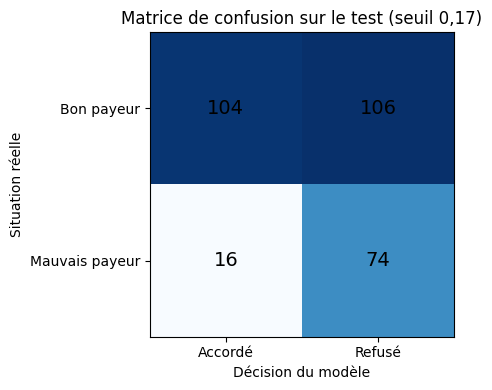

In [24]:
cm = confusion_matrix(y_test, pred_test)
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Accordé", "Refusé"]); ax.set_yticklabels(["Bon payeur", "Mauvais payeur"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
ax.set_title("Matrice de confusion sur le test (seuil 0,17)")
ax.set_xlabel("Décision du modèle")
ax.set_ylabel("Situation réelle")
plt.tight_layout()
plt.savefig("figures/06_matrice_confusion.png", dpi=150)
plt.show()

**Interprétation.** Sur 300 clients de test (dont 90 mauvais payeurs), le modèle accorde à tort 16 crédits à de mauvais payeurs (coût 16 × 5 = 80) et refuse 106 bons clients (coût 106 × 1 = 106). Le rappel des mauvais payeurs est de 82 %, mais plus de la moitié des bons clients est refusée. Le seuil bas (0,17) évite les erreurs les plus coûteuses au prix de nombreux refus, ce qui est cohérent avec la matrice de coûts 5:1.

    C  AUC moyenne (CV)  écart-type
 0.01             0.771       0.016
 0.10             0.792       0.020
 1.00             0.793       0.018
10.00             0.789       0.023


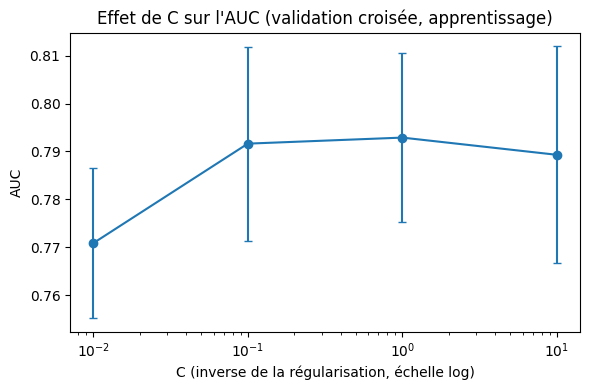

In [25]:
from sklearn.model_selection import cross_val_score

lignes = []
for v in [0.01, 0.1, 1, 10]:
    m = Pipeline([("prep", preprocess), ("clf", LogisticRegression(C=v, max_iter=1000))])
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc")
    lignes.append((v, s.mean(), s.std()))

t = pd.DataFrame(lignes, columns=["C", "AUC moyenne (CV)", "écart-type"])
print(t.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(t["C"], t["AUC moyenne (CV)"], yerr=t["écart-type"], marker="o", capsize=3)
ax.set_xscale("log")
ax.set_title("Effet de C sur l'AUC (validation croisée, apprentissage)")
ax.set_xlabel("C (inverse de la régularisation, échelle log)")
ax.set_ylabel("AUC")
plt.tight_layout()
plt.savefig("figures/07_effet_C_cv.png", dpi=150)
plt.show()

conclusion : Le modèle de scoring avec un seuil optimisé (0,17) réduit le coût moyen de 0,70 à 0,62 sur le test, soit 11 % de moins que la meilleure règle naïve (tout refuser), mais sans atteindre l'objectif fixé de 20 % (0,56). Un seuil de 0,5 serait nettement pire (0,85 en validation), ce qui confirme que le seuil fait partie de la décision. Compte tenu du faible nombre de mauvais payeurs au test (90), cette amélioration reste incertaine.

**Sources**
- Données : German Credit Data, Kaggle (varunchawla30), https://www.kaggle.com/datasets/varunchawla30/german-credit-data, extraites le 17/11/2026. Jeu issu du Statlog German Credit (UCI Machine Learning Repository).
- Documentation : scikit-learn (LogisticRegression, Pipeline, ColumnTransformer, GridSearchCV).
- Support de cours : Tp_ML.ipynb.

**Dépôt :** https://github.com/mizeblina1477encg-png/25007611-mizeblina-grpfin3

**Reproduction.** Cloner le dépôt, installer les dépendances avec `pip install -r requirements.txt`, placer le fichier dans `data/raw/german_credit_data.csv`, puis exécuter le notebook `notebooks/projet_F1.ipynb` avec « Redémarrer et tout exécuter ». Graine fixée à 42.